# 06 · What the calendar explains

Both series follow the calendar, and the surrogate tests of notebook 04 depend on which part
of it is removed. This notebook shows what each part carries. Each series is split by
least squares into

$$x_{s,t} = \underbrace{m_{\text{date}(t)}}_{\text{campaign profile}} +
  \underbrace{w_{\text{weekday}(t)}}_{\text{weekly cycle}} +
  \underbrace{a_s}_{\text{season level}} + \underbrace{\tilde x_{s,t}}_{\text{anomaly}} ,$$

(`src/phc/seasonal.py`): the average shape of the campaign (one value per calendar date),
the day-of-week effect, the level of each season (which comes mostly from normalising each
season by its own maximum) and what remains.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "phc").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from phc.config import CAMPAIGNS, FIG_DIR, TAB_DIR
from phc.granger import load_daily
from phc import seasonal as T

CODES = ["OR", "Mov", "MB", "DJ"]
LABEL = {c: CAMPAIGNS[c].label for c in CODES}
GT_COLOR, MC_COLOR = "#2a6fb0", "#e08a2c"

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
data = {c: load_daily(c) for c in CODES}

## 1. Variance shares

Share of the variance of each series carried by each term (sequential sums of squares, in
the order profile, weekday, season).

In [2]:
shares = pd.concat({LABEL[c]: T.variance_shares(data[c]) for c in CODES}, names=["campaign", "series"])
shares.to_csv(TAB_DIR / "calendar_variance_shares.csv")
shares.round(3)

campaign profile  weekday  season level  anomaly  anomaly SD (points)
campaign     series                                                                       
Octobre Rose GT                 0.736    0.008         0.182    0.074                4.954
             MC                 0.600    0.020         0.039    0.341               11.751
Movember     GT                 0.844    0.017         0.042    0.097                4.969
             MC                 0.152    0.032         0.029    0.787               15.910
Mars Bleu    GT                 0.229    0.087         0.360    0.323                9.855
             MC                 0.219    0.043         0.071    0.667               15.892
Dry January  GT                 0.529    0.002         0.128    0.340               14.345
             MC                 0.285    0.022         0.169    0.525               15.553

The campaign profile carries most of the variance of the search series of Octobre Rose and
Movember, and both series are lower at weekends (next figure).

The weekly cycle matters for a second reason. A season-swap surrogate pairs a season with
another year **at the same calendar dates**, whose days of the week differ. The swap
therefore breaks the weekly cycle shared by the two series, and a test based on it can
mistake that cycle for a link. Notebook 04 (Section 6) quantifies the problem for the
Granger tests.

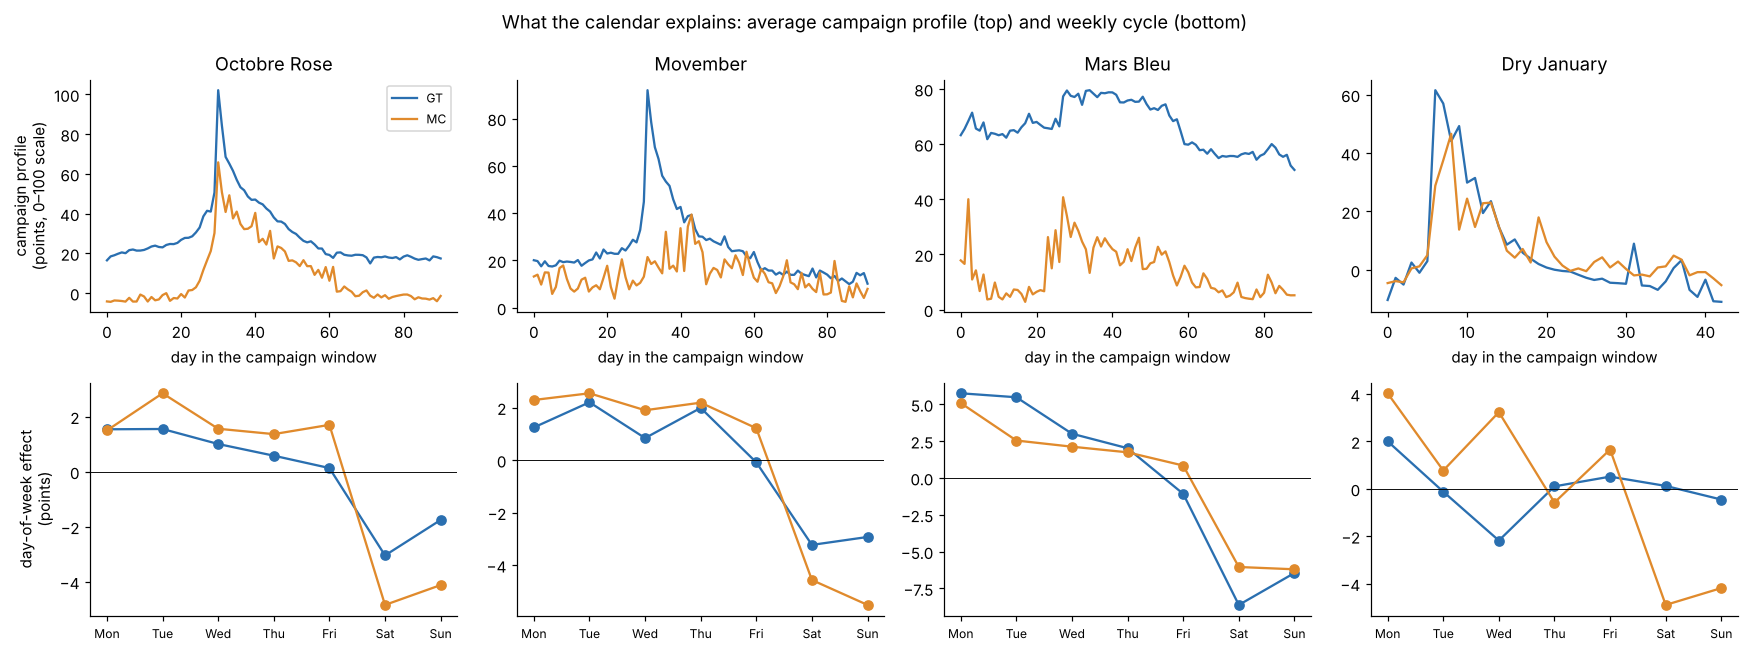

In [3]:
anom, comps = {}, {}
for c in CODES:
    anom[c], comps[c] = T.anomalies(data[c], return_components=True)

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for j, c in enumerate(CODES):
    df = data[c]
    first = df[df["season"] == df["season"].iloc[0]]
    days = np.arange(len(first))
    for col, color, name in (("gt", GT_COLOR, "GT"), ("mc", MC_COLOR, "MC")):
        prof = T.panel(df.assign(v=comps[c][(col, "profile")]), "v")
        axes[0, j].plot(np.nanmean(prof, 0), color=color, lw=1.5, label=name)
        wd = pd.Series(comps[c][(col, "weekday")].to_numpy(), index=df.index.dayofweek).groupby(level=0).mean()
        axes[1, j].plot(range(7), wd.to_numpy(), marker="o", color=color, label=name)
    axes[0, j].set(title=LABEL[c], xlabel="day in the campaign window")
    axes[1, j].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], fontsize=8)
    axes[1, j].axhline(0, color="black", lw=0.6)
axes[0, 0].set_ylabel("campaign profile\n(points, 0–100 scale)")
axes[1, 0].set_ylabel("day-of-week effect\n(points)")
axes[0, 0].legend(fontsize=8)
fig.suptitle("What the calendar explains: average campaign profile (top) and weekly cycle (bottom)")
fig.tight_layout()
fig.savefig(FIG_DIR / "cal01_calendar_components.png", dpi=200, bbox_inches="tight")